In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("Telco-Customer-Churn.csv")

# Display shape and basic details
print("Dataset Shape (Rows, Columns):", df.shape) # Step 1 & 2 requirement
print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nDataset Info:")
df.info()

Dataset Shape (Rows, Columns): (7043, 21)

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Last 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-

In [18]:
# Separate numerical and categorical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical Columns:", num_cols)
print("Categorical Columns:", cat_cols)

# Note: customerID is an identifier, Churn is the potential target variable
print("\nPotential Target Variable: Churn")
print("Non-predictive Identifier Column: customerID")

# Summary statistics for numerical features
print("\nNumerical Statistics:")
display(df.describe())

Numerical Columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges']
Categorical Columns: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']

Potential Target Variable: Churn
Non-predictive Identifier Column: customerID

Numerical Statistics:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [19]:
# Check for missing values in the dataset

# Convert blank spaces in TotalCharges to missing values
df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan)

# Convert TotalCharges from object to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Display missing value count and percentage for each column
missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_count,
    'Missing Percentage (%)': missing_percentage
})

print("Missing values before handling:")
display(missing_summary)

# Create a copy of the original dataset for cleaning
df_clean = df.copy()

# Fill missing TotalCharges values using the median
median_total_charges = df_clean['TotalCharges'].median()
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(
    median_total_charges
)

# Verify that missing values have been handled
print("\nMissing values after handling:")
print(df_clean.isnull().sum())

print("\nTotal missing values after cleaning:",
      df_clean.isnull().sum().sum())

# Check unique values in categorical columns for consistency
cat_cols = df_clean.select_dtypes(include=['object']).columns.tolist()

print("\nUnique categorical values:")
for col in cat_cols:
    print(f"{col}: {df_clean[col].unique()}")

Missing values before handling:


,Missing Values,Missing Percentage (%)
customerID,0,0.000000
gender,0,0.000000
SeniorCitizen,0,0.000000
Partner,0,0.000000
Dependents,0,0.000000
tenure,0,0.000000
PhoneService,0,0.000000
MultipleLines,0,0.000000
InternetService,0,0.000000
OnlineSecurity,0,0.000000



Missing values after handling:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total missing values after cleaning: 0

Unique categorical values:
customerID: ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
gender: ['Female' 'Male']
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
PhoneService: ['No' 'Yes']
MultipleLines: ['No phone service' 'No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes' 'No internet service']
OnlineBackup: ['Yes' 'No' 'No internet service']
DeviceProtection: ['No' 'Yes' 'No int

In [20]:
# Check and drop duplicate records
print("Duplicate Rows Found:", df_clean.duplicated().sum())
df_clean.drop_duplicates(inplace=True)

# Drop non-useful identifier column
if 'customerID' in df_clean.columns:
    df_clean.drop(columns=['customerID'], inplace=True)

# Clean string formatting in categorical columns[cite: 2]
cat_cols = df_clean.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    df_clean[col] = df_clean[col].str.strip()

print("Dataset shape after dropping customerID and duplicate check:", df_clean.shape)


Duplicate Rows Found: 0
Dataset shape after dropping customerID and duplicate check: (7043, 20)


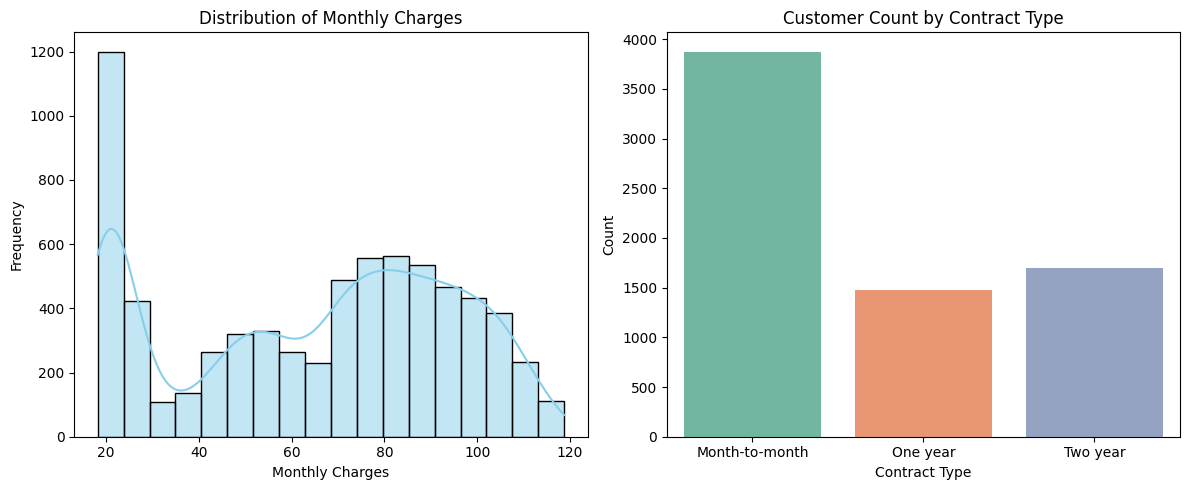

EDA Observations:
1. Monthly charges show a multi-modal distribution with a prominent peak near 20.
2. Month-to-month contracts are significantly more common than one-year or two-year contracts.


In [21]:
plt.figure(figsize=(12, 5))

# Plot 1: Histogram for Numerical Feature (MonthlyCharges)[cite: 2]
plt.subplot(1, 2, 1)
sns.histplot(df_clean['MonthlyCharges'], kde=True, color='skyblue')
plt.title('Distribution of Monthly Charges')
plt.xlabel('Monthly Charges')
plt.ylabel('Frequency')

# Plot 2: Bar Chart for Categorical Feature (Contract)[cite: 2]
plt.subplot(1, 2, 2)
sns.countplot(data=df_clean, x='Contract', hue='Contract', palette='Set2', legend=False)
plt.title('Customer Count by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

# Brief EDA Observations[cite: 2]
print("EDA Observations:")
print("1. Monthly charges show a multi-modal distribution with a prominent peak near 20.")
print("2. Month-to-month contracts are significantly more common than one-year or two-year contracts.")

In [22]:
# Identify target and categorical feature columns[cite: 2]
target_col = 'Churn'
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
multi_cat_cols = [c for c in cat_cols if c not in binary_cols]

# Map binary categories to 0/1[cite: 2]
for col in binary_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].map({'Yes': 1, 'No': 0, 'Male': 1, 'Female': 0})

# Apply One-Hot Encoding for nominal columns with >2 unique categories[cite: 2]
df_clean = pd.get_dummies(df_clean, columns=multi_cat_cols, drop_first=True)

print("Shape after encoding categorical variables:", df_clean.shape)
display(df_clean.head(3))

Shape after encoding categorical variables: (7043, 31)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,False,False,False,False,False,False,False,False,True,False
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,False,False,False,False,False,True,False,False,False,True
2,1,0,0,0,2,1,1,53.85,108.15,1,...,False,False,False,False,False,False,False,False,False,True


In [23]:
# Features to scale (exclude binary target and flags)[cite: 2]
scale_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()
df_clean[scale_cols] = scaler.fit_transform(df_clean[scale_cols])

print("Scaled Numerical Columns Sample:")
display(df_clean[scale_cols].head())

Scaled Numerical Columns Sample:


,tenure,MonthlyCharges,TotalCharges
0,-1.277445,-1.160323,-0.994242
1,0.066327,-0.259629,-0.173244
2,-1.236724,-0.362660,-0.959674
3,0.514251,-0.746535,-0.194766
4,-1.236724,0.197365,-0.940470


In [24]:
# Final validation check[cite: 2, 3]
print("Final Dataset Shape:", df_clean.shape)
print("Total Null Values Remaining:", df_clean.isnull().sum().sum())
print("Total Duplicate Rows:", df_clean.duplicated().sum())

# Save clean CSV file[cite: 3]
df_clean.to_csv('prepared_telco_churn.csv', index=False)
print("\nDataset successfully processed and saved as 'prepared_telco_churn.csv'.")

Final Dataset Shape: (7043, 31)
Total Null Values Remaining: 0
Total Duplicate Rows: 22

Dataset successfully processed and saved as 'prepared_telco_churn.csv'.
